# Blog Writing Agent v3 — Research Setup

This notebook initializes the environment for a LangGraph-based blog-writing agent that researches a topic, gathers supporting sources, and prepares the workflow for article generation.

It imports the required libraries, loads local environment variables from `.env`, and prepares the chat model and search tooling needed by the rest of the pipeline.

Required environment variables:
- `ANTHROPIC_API_KEY`
- `TAVILY_API_KEY`

This is the foundation step for the agent workflow. The next cells will define:
1. the agent state and graph
2. research and drafting nodes
3. execution logic for a specific blog topic

In [153]:
from __future__ import annotations

import ast
import operator
import os
import re
from datetime import date, datetime, timedelta
from pathlib import Path
from typing import TypedDict, List, Optional, Literal, Annotated

from pydantic import BaseModel, Field

from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_anthropic import ChatAnthropic
from langchain_core.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from langchain_tavily import TavilySearch

load_dotenv()  # Load environment variables from .env file

True

## Utility: normalize names to snake_case

This helper converts mixed-case strings, titles, or labels into a consistent `snake_case` format for use in variable names, IDs, or filenames.

Example:
- `Blog Writing Agent v3` → `blog_writing_agent_v3`
- `My API Key` → `my_api_key`

In [154]:
import re

def to_snake_case(text):
    words = re.findall(r'[a-zA-Z0-9]+', text)
    return '_'.join(word.lower() for word in words)

## Core data model for the research-driven writing workflow

This cell defines the structured schema used throughout the LangGraph workflow. It establishes the data contracts for:
- the overall article plan (`Plan`)
- each article section (`Task`)
- research evidence (`EvidenceItem`, `EvidencePack`)
- the router decision (`RouterDecision`)
- the runtime state passed between workflow nodes (`State`)

The `State` object is the central shared memory of the pipeline. It tracks the topic, research mode, queries, evidence gathered, planning metadata, recency constraints, generated section content, and the final blog article.

This layer is essential because it keeps research, planning, drafting, and final assembly consistent across the workflow.

In [155]:
# Task object definition. This should now contain additional attributes for research.
class Task(BaseModel):
    id: int
    title: str
    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        description="3 to 7 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(..., description="Target word count for this section (120-550).")
    tags: List[str] = Field(default_factory=list)
    requires_research: bool = False
    requires_citations: bool = False
    requires_code: bool = False


class Plan(BaseModel):
    blog_title: str
    audience: str = Field(..., description="Who this blog is for.")
    tone: str = Field(..., description="Writing tone (e.g., practical, crisp).")
    blog_kind: Literal["explainer", "tutorial", "news_roundup", "comparison", "system_design"] = "explainer"
    constraints: List[str] = Field(default_factory=list)
    tasks: List[Task]

class EvidenceItem(BaseModel):
    title: str
    url: str
    published_at: Optional[str] = None  # keep if Tavily provides; DO NOT rely on it
    snippet: Optional[str] = None
    source: Optional[str] = None


class RouterDecision(BaseModel):
    needs_research: bool
    mode: Literal["closed_book", "hybrid", "open_book"]
    queries: List[str] = Field(default_factory=list)


class EvidencePack(BaseModel):
    evidence: List[EvidenceItem] = Field(default_factory=list)



class State(TypedDict):
    topic: str

    # routing / research
    mode: str
    needs_research: bool
    queries: List[str]
    evidence: List[EvidenceItem]
    plan: Optional[Plan]

    # recency control
    as_of: str          # ISO date, e.g, 2026-06-30
    recency_days: int   # 7 for weekly news, 30 for hybrid, etc.

    # workers
    sections: Annotated[List[tuple[int, str]], operator.add]  # (task_id, section_md)
    section_issues: Annotated[List[tuple[int, str]], operator.add]  # (task_id, problem) left after retry
    final: str
    
    # tagging
    tags: List[str]
    output_path: str

## Models (Claude, one per role)

Each node gets the model that fits its job:
- **Router / research extraction** → Haiku: cheap, structured, high-volume steps.
- **Planner** → Sonnet: every section inherits the outline, so quality matters here. Switch to `claude-opus-5-5` if plans feel generic.
- **Writer (workers)** → Sonnet with a slightly higher temperature so prose reads less templated.

Note: at CoS the standard is Gemini; this notebook uses Claude for personal experimentation.

In [156]:
router_llm   = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=1024)
research_llm = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=4096)
planner_llm  = ChatAnthropic(model="claude-sonnet-5-5", max_tokens=4096)
writer_llm   = ChatAnthropic(model="claude-sonnet-5-5", max_tokens=8192)  # headroom: a section with code can run long
tagger_llm   = ChatAnthropic(model="claude-haiku-5-5",  max_tokens=1024)

## ROUTING MECHANISM

In [157]:
ROUTER_SYS_PROMPT = """
You are a routing module for a technical blog planner.
Decide whether web research is needed BEFORE planning.
Modes:
- closed_book (needs_research=false): 
    Evergreen topics where correctness does not depend on recent facts. (concepts, fundamentals)
- hybrid (needs_research=true): 
    Mostly evergreen but needs up-to-date examples/tools/models to be useful
- open_book (needs_research=true): 
    Mostly volatile: weekly round-ups, "this week", "latest", rankings, pricing, policy/regulation.

If needs_research=true:
- Output 3-10 high-signal queries.
- Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
- If user asked for "last week" or "this week" or "latest", reflect that constraint IN THE QUERIES.
"""

def router_node(state: State) -> dict:
    topic = state["topic"]
    decider = router_llm.with_structured_output(RouterDecision, method="json_schema")
    decision = decider.invoke(
        [
            SystemMessage(content=ROUTER_SYS_PROMPT),
            HumanMessage(content=f"Topic: {topic}\nAs-of date: {state['as_of']}"),
        ]
    )

    # Set default recency window based on mode
    if decision.mode == "open_book":
        recency_days = 7
    elif decision.mode == "hybrid":
        recency_days = 45
    else:
        recency_days = 3650

    return {
        "needs_research": decision.needs_research,
        "mode": decision.mode,
        "queries": decision.queries,
        "recency_days": recency_days,
    }

def route_next(state: State) -> str:
    return "research" if state["needs_research"] else "orchestrator"

## RESEARCH NODE (uses Tavily)

In [158]:
def _tavily_search(query: str, max_results: int = 5) -> List[dict]:
    
    tool = TavilySearch(max_results=max_results)
    response = tool.invoke({"query": query})
    if not isinstance(response, dict):
        raise TypeError(f"Expected a Tavily response dict, got {type(response).__name__}")
    if "error" in response:
        raise RuntimeError(f"Tavily search failed: {response['error']}")

    results = response.get("results", [])
    if not isinstance(results, list):
        raise TypeError("Expected Tavily response 'results' to be a list")

    normalized: List[dict] = []
    for r in results or []:
        if not isinstance(r, dict):
            raise TypeError(f"Expected each Tavily result to be a dict, got {type(r).__name__}")
        normalized.append(
            {
                "title": r.get("title") or "",
                "url": r.get("url") or "",
                "snippet": r.get("content") or r.get("snippet") or "",
                "published_at": r.get("published_date") or r.get("published_at"),
                "source": r.get("source"),
            }
        )
    return normalized

def _iso_to_date(s: Optional[str]) -> Optional[date]:
    if not s:
        return None
    try:
        return date.fromisoformat(s[:10])
    except Exception:
        return None

RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- Drop results that are not specifically about the topic (company homepages, generic
  encyclopedia pages, unrelated news) even if they come from an authoritative domain.
- Snippets must reflect what the source actually says; never add claims not in the raw result.
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short (1-3 sentences) but keep the key factual claims.
- Deduplicate by URL.
"""


def research_node(state: State) -> dict:
    queries = (state.get("queries", []) or [])[:10]
    max_results = 6

    raw_results: List[dict] = []
    for q in queries:
        raw_results.extend(_tavily_search(q, max_results=max_results))

    if not raw_results:
        return {"evidence": []}

    extractor = research_llm.with_structured_output(EvidencePack, method="json_schema")
    pack = extractor.invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(
                content=(
                    f"As-of date: {state['as_of']}\n"
                    f"Recency days: {state['recency_days']}\n\n"
                    f"Raw results:\n{raw_results}"
                )
            ),
        ]
    )

    # Deduplicate by URL
    dedup = {}
    for e in pack.evidence:
        if e.url:
            dedup[e.url] = e
    evidence = list(dedup.values())

    # HARD RECENCY FILTER for open_book weekly roundup:
    # keep only items with a parseable ISO date and within the window.
    mode = state.get("mode", "closed_book")
    if mode == "open_book":
        as_of = date.fromisoformat(state["as_of"])
        cutoff = as_of - timedelta(days=int(state["recency_days"]))
        fresh: List[EvidenceItem] = []
        for e in evidence:
            d = _iso_to_date(e.published_at)
            if d and d >= cutoff:
                fresh.append(e)
        evidence = fresh

    return {"evidence": evidence}


## ORCHRESTRATION (PLANNING)

In [159]:
# Orchestration (Planning)

ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5-9 sections (tasks) suitable for the topic and audience.
- Each task must include:
    1) goal (1 sentence)
    2) 3-6 bullets that are concrete, specific, and non-overlapping
    3) target word count (120-550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
    * minimal code sketch / MWE (set requires_code=True for that section)
    * edge cases / failure modes
    * performance/cost considerations
    * security/privacy considerations (if relevant)
    * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
    - Use evidence for up-to-date examples (models/tools/releases) in bullets.
    - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Only use blog_kind = "news_roundup" in mode open_book. Never choose it for closed_book or hybrid.
- Mode open_book:
    - Set blog_kind = "news_roundup".
    - Every section is about summarizing events + implications.
    - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
    - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources" and includes only what can be supported.

Output must strictly match the Plan schema.
"""

def orchestrator_node(state: State) -> dict:
    planner = planner_llm.with_structured_output(Plan, method="json_schema")
    evidence = state.get("evidence", [])
    mode = state.get("mode", "closed_book")

    # Force blog_kind for open_book
    forced_kind = "news_roundup" if mode == "open_book" else None

    plan = planner.invoke(
        [
            SystemMessage(content=ORCH_SYSTEM),
            HumanMessage(
                content=(
                    f"Topic: {state['topic']}\n"
                    f"Mode: {mode}\n"
                    f"As-of: {state['as_of']} (recency_days={state['recency_days']})\n"
                    f"{'Force blog_kind=news_roundup' if forced_kind else ''}\n\n"
                    f"Evidence (ONLY use for fresh claims; may be empty):\n"
                    f"{[e.model_dump() for e in evidence][:16]}\n\n"
                    f"Instruction: If mode=open_book, your plan must NOT drift into a tutorial."
                )
            ),
        ]
    )

    # Ensure open_book forces the kind even if model forgets,
    # and that non-open_book modes never drift into a news roundup.
    if forced_kind:
        plan.blog_kind = "news_roundup"
    elif plan.blog_kind == "news_roundup":
        plan.blog_kind = "explainer"
        plan.constraints = [c for c in plan.constraints if "tutorial" not in c.lower()]

    return {"plan": plan}

## FANOUT (Workers routing)

In [160]:
def fanout(state: State):
    assert state["plan"] is not None
    return [
        Send(
            "worker",
            {
                "task": task.model_dump(),
                "topic": state["topic"],
                "mode": state["mode"],
                "as_of": state["as_of"],
                "recency_days": state["recency_days"],
                "plan": state["plan"].model_dump(),
                "evidence": [e.model_dump() for e in state.get("evidence", [])],
            },
        )
        for task in state["plan"].tasks
    ]

## WORKER NODE

In [161]:
WORKER_RETRIES = 1


def _check_section(md: str, requires_code: bool, response_metadata: dict) -> List[str]:
    """Return a list of problems with a generated section; empty means it passed."""
    problems: List[str] = []

    stop = (response_metadata or {}).get("stop_reason")
    if stop and stop != "end_turn":
        usage = (response_metadata or {}).get("usage", {})
        problems.append(f"response stopped with stop_reason={stop!r} (usage: {usage})")

    if md.count("```") % 2:
        problems.append("a code block is not closed (odd number of ``` fences)")

    blocks = re.findall(r"```([\w+-]*)[^\n]*\n(.*?)```", md, flags=re.S)
    if requires_code and not blocks:
        problems.append("requires_code is true but the section has no code block")

    for lang, body in blocks:
        if lang.lower() in ("python", "py"):
            try:
                ast.parse(body)
            except SyntaxError as e:
                problems.append(f"python code block does not parse: {e.msg} (line {e.lineno})")

    return problems


WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard (prevents mid-blog topic drift):
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book (weekly news):
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true (hybrid sections):
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning (concepts, intuition) is OK without citations unless requires_citations is true.
- Only cite a URL for a claim its Snippet actually supports. If no snippet supports a specific
  outside-world claim (a product feature, integration, report, number), leave the claim out
  rather than citing a loosely related URL.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.
- Every code block must be complete and syntactically valid, and must end with a closing fence.
- Keep each snippet under ~40 lines. If the full example would be longer, show the core logic
  and describe the rest in prose rather than starting something you can't finish.
- Helpers the snippet calls but doesn't define must appear as clearly marked stubs,
  e.g. `def query_tsdb(params): ...  # your historian client`.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker_node(payload: dict) -> dict:

    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [EvidenceItem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closed_book")
    as_of = payload.get("as_of")
    recency_days = payload.get("recency_days")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    # Provide a compact evidence list for citation use
    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}\n  Snippet: {e.snippet or '(none)'}"
            for e in evidence[:20]
        )

    prompt = (
        f"Blog title: {plan.blog_title}\n"
        f"Audience: {plan.audience}\n"
        f"Tone: {plan.tone}\n"
        f"Blog kind: {plan.blog_kind}\n"
        f"Constraints: {plan.constraints}\n"
        f"Topic: {topic}\n"
        f"Mode: {mode}\n"
        f"As-of: {as_of} (recency_days={recency_days})\n\n"
        f"Section title: {task.title}\n"
        f"Goal: {task.goal}\n"
        f"Target words: {task.target_words}\n"
        f"Tags: {task.tags}\n"
        f"requires_research: {task.requires_research}\n"
        f"requires_citations: {task.requires_citations}\n"
        f"requires_code: {task.requires_code}\n"
        f"Bullets:{bullets_text}\n\n"
        f"Evidence (ONLY use these URLs when citing; each Snippet shows what that source supports):\n{evidence_text}\n"
    )

    # Write, check, and retry once with the problems spelled out
    feedback = ""
    problems: List[str] = []
    for attempt in range(1 + WORKER_RETRIES):
        resp = writer_llm.invoke([SystemMessage(content=WORKER_SYSTEM), HumanMessage(content=prompt + feedback)])
        section_md = resp.text.strip()  # .text: Claude content can be a list of blocks
        problems = _check_section(section_md, task.requires_code, resp.response_metadata)
        if not problems:
            break
        feedback = (
            "\n\nYOUR PREVIOUS ATTEMPT HAD THESE PROBLEMS. Rewrite the whole section and fix them:\n- "
            + "\n- ".join(problems)
            + "\nKeep code blocks short and complete."
        )

    # Still broken after retry: close any open fence so the rest of the post renders, and record it
    if section_md.count("```") % 2:
        section_md += "\n```"

    return {
        "sections": [(task.id, section_md)],
        "section_issues": [(task.id, p) for p in problems],
    }

## REDUCER NODE

In [162]:
def reducer_node(state: State) -> dict:
    plan = state["plan"]
    if plan is None:
        raise ValueError("Reducer called without a plan.")

    ordered_sections = [md for _, md in sorted(state["sections"], key=lambda x: x[0])]
    body = "\n\n".join(ordered_sections).strip()
    final_md = f"# {plan.blog_title}\n\n{body}\n"

    return {"final": final_md}

## TAGGER NODE

In [163]:
# CATEGORIES = [
#     "AI & Machine Learning",
#     "Data Engineering",
#     "Software Architecture",
#     "Cloud & DevOps",
#     "Developer Tools",
#     "Industry News",
#     "Security & Privacy"
# ]

MIN_TAGS, MAX_TAGS = 5, 8


class BlogTags(BaseModel):
    tags: List[str] = Field(
        ...,
        description=f"{MIN_TAGS}-{MAX_TAGS} specific tags, lowercase and hyphen-separated, e.g. 'graph-rag'.",
    )


TAGGER_SYSTEM = f"""You assign tags to a finished technical blog post.

Tags:
- {MIN_TAGS}-{MAX_TAGS} tags, lowercase, hyphen-separated (e.g. "graph-rag", "langgraph", "vector-search").
- Always include the post's main subject as a tag.
- Tags must reflect what the post actually covers in depth, not things mentioned in passing.
- Prefer specific technologies, techniques and concepts. Avoid generic tags like "ai", "technology", "blog", "guide", "2026".
- No near-duplicates (e.g. not both "rag" and "retrieval-augmented-generation"; pick the common short form).
"""


def _normalize_tag(t: str) -> str:
    return re.sub(r"[^a-z0-9]+", "-", t.lower()).strip("-")


def _yaml_str(s: str) -> str:
    return '"' + s.replace("\\", "\\\\").replace('"', '\\"') + '"'


def tagger_node(state: State) -> dict:
    plan = state["plan"]
    if plan is None:
        raise ValueError("Tagger called without a plan.")

    # Section titles + planner tags are strong hints for what the post covers
    outline = "\n".join(f"- {t.title} (planner tags: {', '.join(t.tags) or 'none'})" for t in plan.tasks)

    tagger = tagger_llm.with_structured_output(BlogTags, method="json_schema")
    result = tagger.invoke(
        [
            SystemMessage(content=TAGGER_SYSTEM),
            HumanMessage(
                content=(
                    f"Title: {plan.blog_title}\n"
                    f"Blog kind: {plan.blog_kind}\n"
                    f"Audience: {plan.audience}\n"
                    f"Topic request: {state['topic']}\n\n"
                    f"Outline:\n{outline}\n\n"
                    f"Post (may be truncated):\n{state['final'][:12000]}"
                )
            ),
        ]
    )

    # Normalize, dedupe (order-preserving), drop generic tags, cap
    generic = {"ai", "technology", "tech", "blog", "guide", "tutorial", "news"}
    tags: List[str] = []
    for t in result.tags:
        n = _normalize_tag(t)
        if n and n not in generic and n not in tags:
            tags.append(n)
    tags = tags[:MAX_TAGS]

    front_matter = (
        "---\n"
        f"title: {_yaml_str(plan.blog_title)}\n"
        f"date: {state['as_of']}\n"
        f"blog_kind: {plan.blog_kind}\n"
        "tags: [" + ", ".join(tags) + "]\n"
        "---\n\n"
    )

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    output_path = f"blog_posts/{timestamp}_{to_snake_case(plan.blog_title)}.md"
    Path(output_path).write_text(front_matter + state["final"], encoding="utf-8")

    return {"tags": tags, "output_path": output_path}

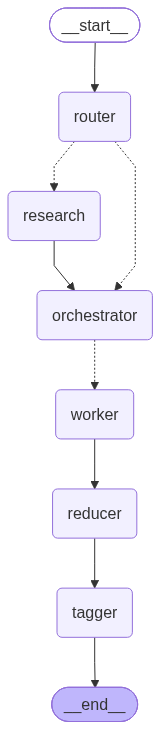

In [164]:
g = StateGraph(State)
g.add_node("router", router_node)
g.add_node("research", research_node)
g.add_node("orchestrator", orchestrator_node)
g.add_node("worker", worker_node)
g.add_node("reducer", reducer_node)
g.add_node("tagger", tagger_node)

g.add_edge(START, "router")
g.add_conditional_edges("router", route_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", "tagger")
g.add_edge("tagger", END)

app = g.compile()

app

## RUN THE CODE

In [165]:
import json


def _to_jsonable(obj):
    """Convert graph state (Pydantic models, tuples, etc.) into JSON-safe data."""
    if isinstance(obj, BaseModel):
        return obj.model_dump(mode="json")
    if isinstance(obj, dict):
        return {str(k): _to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple, set)):
        return [_to_jsonable(v) for v in obj]
    if obj is None or isinstance(obj, (str, int, float, bool)):
        return obj
    return str(obj)


def _save_json(path: Path, data) -> None:
    path.write_text(json.dumps(_to_jsonable(data), indent=2, ensure_ascii=False), encoding="utf-8")


def _snapshot_name(node: str, update: dict) -> str:
    # Parallel workers all share the node name "worker"; tell them apart by task id
    if node == "worker" and update.get("sections"):
        return f"worker_task{update['sections'][0][0]:02d}"
    return node

In [166]:
def run(topic: str, as_of: Optional[str] = None, qa_dir: str = "runs"):
    if as_of is None:
        as_of = date.today().isoformat()

    slug = to_snake_case(topic)
    if len(slug) > 50:
        slug = slug[:50].rsplit("_", 1)[0]   # cut at the last full word
    slug = slug.strip("_")

    run_dir = Path(qa_dir) / f"{datetime.now():%Y%m%d-%H%M%S}_{slug}"
    run_dir.mkdir(parents=True, exist_ok=True)

    initial_state = {
        "topic": topic,
        "mode": "",
        "needs_research": False,
        "queries": [],
        "evidence": [],
        "plan": None,
        "as_of": as_of,
        "recency_days": 7,   # router may overwrite
        "sections": [],
        "section_issues": [],
        "final": "",
        "tags": [],
        "output_path": "",
    }

    config = {"max_concurrency": 3}  # caps parallel workers to stay under Anthropic rate limits

    step = 0
    pending: List[tuple[str, dict]] = []
    out = None
    for mode, chunk in app.stream(
        initial_state,
        config={"max_concurrency": 3},
        stream_mode=["updates", "values"],
    ):
        if mode == "updates":
            for node, update in chunk.items():
                pending.append((node, update or {}))
            continue

        # mode == "values": the step is complete, write one file per node that ran in it
        out = chunk
        if not pending:
            _save_json(run_dir / f"{step:02d}_input.json", {"step": step, "node": "input", "state": chunk})
        for node, update in pending:
            _save_json(
                run_dir / f"{step:02d}_{_snapshot_name(node, update)}.json",
                {"step": step, "node": node, "update": update, "state_after": chunk},
            )
        pending = []
        step += 1

    _save_json(run_dir / "final_state.json", out)

    plan: Plan = out["plan"]
    print("\n" + "=" * 100)
    print("TOPIC:", topic)
    print("AS_OF:", out.get("as_of"), "RECENCY_DAYS:", out.get("recency_days"))
    print("MODE:", out.get("mode"))
    print("BLOG_KIND:", plan.blog_kind)
    print("NEEDS_RESEARCH:", out.get("needs_research"))
    print("QUERIES:", (out.get("queries") or [])[:6])
    print("EVIDENCE_COUNT:", len(out.get("evidence", [])))
    if out.get("evidence"):
        print("EVIDENCE_SAMPLE:", [e.model_dump() for e in out["evidence"][:2]])
    print("TASKS:", len(plan.tasks))
    issues = out.get("section_issues", [])
    print("SECTION_ISSUES:", len(issues) or "none")
    for task_id, problem in issues:
        print(f"  - task {task_id}: {problem}")
    print("TAGS:", out.get("tags"))
    print("SAVED_TO:", out.get("output_path"), f"({len(out.get('final', ''))} chars)")
    print("QA_SNAPSHOTS:", run_dir)
    print("=" * 100 + "\n")

    return out

In [167]:
# run("Explain and opine on how GenAI and Agentic AI can help with enhancing IoT as a field")


In [168]:
# # Tutorial
# output_2 = run(
#     "Tutorial: build a LangGraph agent that uses Claude with tool calling and a SQLite "
#     "checkpointer. Step-by-step, with runnable code. Audience: Python devs new to LangGraph."
# )


In [169]:
output_3 = run(
    "Tutorial: build a LangGraph pipeline that takes a set of theses, summarizes each one in parallel "
    "using Send fan-out, then runs two independent groupings side by side: by research area "
    "(an LLM clusters all summaries and assigns each thesis to one area, validated in code) and by "
    "advisor (grouped in code from metadata, with an LLM-written profile per advisor). Cover the join "
    "edge that waits for both branches before writing a report, structured output with Pydantic, and "
    "handling co-advised theses. Include runnable Python code. "
    "Audience: Python developers who know LangChain basics but are new to LangGraph."
)


TOPIC: Tutorial: build a LangGraph pipeline that takes a set of theses, summarizes each one in parallel using Send fan-out, then runs two independent groupings side by side: by research area (an LLM clusters all summaries and assigns each thesis to one area, validated in code) and by advisor (grouped in code from metadata, with an LLM-written profile per advisor). Cover the join edge that waits for both branches before writing a report, structured output with Pydantic, and handling co-advised theses. Include runnable Python code. Audience: Python developers who know LangChain basics but are new to LangGraph.
AS_OF: 2026-10-13 RECENCY_DAYS: 45
MODE: hybrid
BLOG_KIND: tutorial
NEEDS_RESEARCH: True
QUERIES: ['LangGraph Send API parallel fan-out map-reduce example documentation', 'LangGraph deferred nodes join edge waiting for multiple parallel branches', 'LangGraph StateGraph add_conditional_edges Send list of nodes latest release notes', 'LangChain with_structured_output Pydantic model 